## BRCA Feature Engineering

Exploring biologically valid features that may provide more info or non-linear relationships for BRCA1 variant classification

goal is to create and validate interpretable features; understand its distribution and relationship with existing features; identify redundany or unnecessary derived features and decide on potential features to be included in processed dataset 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

df = pd.read_csv("../data/raw/dataset.csv")
df.shape, df.columns

((1600, 24),
 Index(['variation_id', 'gene_symbol', 'protein_change', 'protein_position',
        'ref_aa', 'alt_aa', 'clinical_significance', 'domain', 'plddt',
        'is_stop_gained', 'is_frameshift', 'is_splice_region', 'label',
        'pos_norm', 'distance_to_domain', 'plddt_at_pos', 'plddt_window11',
        'hydro_delta', 'charge_delta', 'volume_delta', 'domain_BRCT1',
        'domain_BRCT2', 'domain_OTHER', 'domain_RING'],
       dtype='str'))

In [2]:
df.head()

,variation_id,gene_symbol,protein_change,protein_position,ref_aa,alt_aa,clinical_significance,domain,plddt,is_stop_gained,is_frameshift,is_splice_region,label,pos_norm,distance_to_domain,plddt_at_pos,plddt_window11,hydro_delta,charge_delta,volume_delta,domain_BRCT1,domain_BRCT2,domain_OTHER,domain_RING
0,100000,BRCA1,p.C176G,176,C,G,Benign,OTHER,61.795453,0,0,0,0,0.094471,67,52.778104,57.752886,2.9,0,48.4,False,False,True,False
1,100001,BRCA1,p.F773W,773,F,W,Benign,OTHER,50.859371,0,0,0,0,0.414922,664,59.417299,49.856908,3.7,0,37.9,False,False,True,False
2,100002,BRCA1,p.R1244W,1244,R,W,Benign,OTHER,54.256865,0,0,0,0,0.667740,402,46.864676,51.135601,3.6,1,54.4,False,False,True,False
3,100003,BRCA1,p.L36C,36,L,C,Pathogenic,RING,87.909717,0,0,0,1,0.019324,0,89.439383,83.145249,1.3,0,58.2,False,False,False,True
4,100004,BRCA1,p.I1205V,1205,I,V,Likely benign,OTHER,63.506025,0,0,0,0,0.646806,441,63.869783,56.117647,0.3,0,26.7,False,False,True,False


Existing important features -

#### Positional features
- `protein_position`
- `pos_norm`
- `distance_to_domain`
- `domain`

#### Structural features
- `plddt`
- `plddt_at_pos`
- `plddt_window11`

#### Amino-acid substitution features
- `ref_aa`
- `alt_aa`
- `hydro_delta`
- `charge_delta`
- `volume_delta`

#### Variant consequence flags
- `is_stop_gained`
- `is_frameshift`
- `is_splice_region`


### Derived features exploration

In [3]:
# plddt_delta = plddt_at_po - plddt_wondow11
df["plddt_delta"] = (df["plddt_at_pos"] - df["plddt_window11"])
df[["protein_position","plddt_at_pos","plddt_window11", "plddt_delta"]].head(10)

,protein_position,plddt_at_pos,plddt_window11,plddt_delta
0,176,52.778104,57.752886,-4.974782
1,773,59.417299,49.856908,9.560391
2,1244,46.864676,51.135601,-4.270925
3,36,89.439383,83.145249,6.294134
4,1205,63.869783,56.117647,7.752136
5,332,43.476604,45.877090,-2.400485
6,1653,90.494384,91.529545,-1.035160
7,1033,55.980145,55.209197,0.770949
8,1630,58.053104,58.717517,-0.664412
9,381,49.492464,44.857150,4.635313


In [4]:
# Assuming that plddt_window11 is the avg of 10 neighboring residues + the residue itself
df["plddt_neighbor_mean_est"] = ((df["plddt_window11"] * 11) - df["plddt_at_pos"]) / 10

df[["protein_position","plddt_at_pos","plddt_window11","plddt_neighbor_mean_est"]].head(10)

,protein_position,plddt_at_pos,plddt_window11,plddt_neighbor_mean_est
0,176,52.778104,57.752886,58.250364
1,773,59.417299,49.856908,48.900869
2,1244,46.864676,51.135601,51.562693
3,36,89.439383,83.145249,82.515836
4,1205,63.869783,56.117647,55.342433
5,332,43.476604,45.877090,46.117138
6,1653,90.494384,91.529545,91.633061
7,1033,55.980145,55.209197,55.132102
8,1630,58.053104,58.717517,58.783958
9,381,49.492464,44.857150,44.393619


In [5]:
# plddt score ranges from 0 to 100:
df[(df["plddt_neighbor_mean_est"] < 0) |(df["plddt_neighbor_mean_est"] > 100)][["protein_position","plddt_at_pos","plddt_window11","plddt_neighbor_mean_est"]]

,protein_position,plddt_at_pos,plddt_window11,plddt_neighbor_mean_est


In [6]:
df["plddt_neighbor_mean_est"].describe().round(2)

count    1600.00
mean       57.51
std        13.57
min        39.87
25%        47.53
50%        54.61
75%        59.90
max        93.75
Name: plddt_neighbor_mean_est, dtype: float64

In [7]:
df["plddt_neighbor_delta"] = (df["plddt_at_pos"] -df["plddt_neighbor_mean_est"])
df["plddt_neighbor_delta"].describe().round(2)

count    1600.00
mean        0.14
std         6.35
min       -24.95
25%        -4.19
50%         0.20
75%         4.18
max        19.36
Name: plddt_neighbor_delta, dtype: float64

positive value - current residue has higher confidence than neighboring residues

negative value - current residue has lower confidence than neighboring residues

near zero - current residue is similar to its surrounding structural context

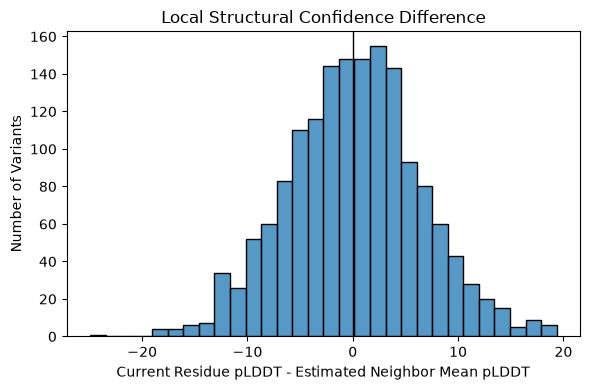

In [8]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df,x="plddt_neighbor_delta",bins=30)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Current Residue pLDDT - Estimated Neighbor Mean pLDDT")
plt.ylabel("Number of Variants")
plt.title("Local Structural Confidence Difference")
plt.tight_layout()
plt.show()

In [9]:
df.loc[(df["protein_position"] <= 10)|(df["protein_position"] >= 1853),["protein_position","plddt_at_pos","plddt_window11","plddt_neighbor_mean_est","plddt_neighbor_delta"]].sort_values("protein_position")

,protein_position,plddt_at_pos,plddt_window11,plddt_neighbor_mean_est,plddt_neighbor_delta
258,1,84.228334,83.196227,83.093016,1.135318
181,5,72.841911,82.239091,83.178809,-10.336899
383,5,72.841911,82.239091,83.178809,-10.336899
216,7,78.063234,83.134328,83.641438,-5.578204
628,7,78.063234,83.134328,83.641438,-5.578204
507,8,89.028046,83.635764,83.096536,5.931510
1085,8,89.028046,83.635764,83.096536,5.931510
1525,9,73.305762,84.127884,85.210096,-11.904334
1363,1853,73.294016,69.384120,68.993130,4.300886
664,1854,74.224780,66.973471,66.248340,7.976440


In [10]:
df["in_functional_domain"] = (df["domain"] != "OTHER").astype(int)

In [11]:
np.allclose(df["plddt_neighbor_delta"],1.1 * df["plddt_delta"]), df[["plddt_delta", "plddt_neighbor_delta"]].corr()

(True,
                       plddt_delta  plddt_neighbor_delta
 plddt_delta                   1.0                   1.0
 plddt_neighbor_delta          1.0                   1.0)

hydro_delta, charge_delta, volume_delta - chemical change between the reference and alternate amino acid

`BLOSUM62` score - how acceptable is this amino acid substituion;<br>

**BLOcks SUbstitution Matrix**

Citation - 
- [https://www.labxchange.org/library/items/lb:LabXchange:24d0ec21:lx_image:1](https://www.labxchange.org/library/items/lb:LabXchange:24d0ec21:lx_image:1)
- [https://en.wikipedia.org/wiki/BLOSUM](https://en.wikipedia.org/wiki/BLOSUM)

range:  -4 to +11

higher BLOSUM62 score - substitution is relatively conservative / commonly observed

lower or negative score - substitution is less evolutionarily favored



In [12]:
# universal BLOSUM matrix:

amino_acids = [
    "A", "R", "N", "D", "C",
    "Q", "E", "G", "H", "I",
    "L", "K", "M", "F", "P",
    "S", "T", "W", "Y", "V"
]

blosum62_values = [
    [ 4, -1, -2, -2,  0, -1, -1,  0, -2, -1, -1, -1, -1, -2, -1,  1,  0, -3, -2,  0],
    [-1,  5,  0, -2, -3,  1,  0, -2,  0, -3, -2,  2, -1, -3, -2, -1, -1, -3, -2, -3],
    [-2,  0,  6,  1, -3,  0,  0,  0,  1, -3, -3,  0, -2, -3, -2,  1,  0, -4, -2, -3],
    [-2, -2,  1,  6, -3,  0,  2, -1, -1, -3, -4, -1, -3, -3, -1,  0, -1, -4, -3, -3],
    [ 0, -3, -3, -3,  9, -3, -4, -3, -3, -1, -1, -3, -1, -2, -3, -1, -1, -2, -2, -1],
    [-1,  1,  0,  0, -3,  5,  2, -2,  0, -3, -2,  1,  0, -3, -1,  0, -1, -2, -1, -2],
    [-1,  0,  0,  2, -4,  2,  5, -2,  0, -3, -3,  1, -2, -3, -1,  0, -1, -3, -2, -2],
    [ 0, -2,  0, -1, -3, -2, -2,  6, -2, -4, -4, -2, -3, -3, -2,  0, -2, -2, -3, -3],
    [-2,  0,  1, -1, -3,  0,  0, -2,  8, -3, -3, -1, -2, -1, -2, -1, -2, -2,  2, -3],
    [-1, -3, -3, -3, -1, -3, -3, -4, -3,  4,  2, -3,  1,  0, -3, -2, -1, -3, -1,  3],
    [-1, -2, -3, -4, -1, -2, -3, -4, -3,  2,  4, -2,  2,  0, -3, -2, -1, -2, -1,  1],
    [-1,  2,  0, -1, -3,  1,  1, -2, -1, -3, -2,  5, -1, -3, -1,  0, -1, -3, -2, -2],
    [-1, -1, -2, -3, -1,  0, -2, -3, -2,  1,  2, -1,  5,  0, -2, -1, -1, -1, -1,  1],
    [-2, -3, -3, -3, -2, -3, -3, -3, -1,  0,  0, -3,  0,  6, -4, -2, -2,  1,  3, -1],
    [-1, -2, -2, -1, -3, -1, -1, -2, -2, -3, -3, -1, -2, -4,  7, -1, -1, -4, -3, -2],
    [ 1, -1,  1,  0, -1,  0,  0,  0, -1, -2, -2,  0, -1, -2, -1,  4,  1, -3, -2, -2],
    [ 0, -1,  0, -1, -1, -1, -1, -2, -2, -1, -1, -1, -1, -2, -1,  1,  5, -2, -2,  0],
    [-3, -3, -4, -4, -2, -2, -3, -2, -2, -3, -2, -3, -1,  1, -4, -3, -2, 11,  2, -3],
    [-2, -2, -2, -3, -2, -1, -2, -3,  2, -1, -1, -2, -1,  3, -3, -2, -2,  2,  7, -1],
    [ 0, -3, -3, -3, -1, -2, -2, -3, -3,  3,  1, -2,  1, -1, -2, -2,  0, -3, -1,  4]
]

blosum62 = pd.DataFrame(blosum62_values,index=amino_acids,columns=amino_acids)
blosum62

,A,R,N,D,C,Q,E,G,H,I,L,K,M,F,P,S,T,W,Y,V
A,4,-1,-2,-2,0,-1,-1,0,-2,-1,-1,-1,-1,-2,-1,1,0,-3,-2,0
R,-1,5,0,-2,-3,1,0,-2,0,-3,-2,2,-1,-3,-2,-1,-1,-3,-2,-3
N,-2,0,6,1,-3,0,0,0,1,-3,-3,0,-2,-3,-2,1,0,-4,-2,-3
D,-2,-2,1,6,-3,0,2,-1,-1,-3,-4,-1,-3,-3,-1,0,-1,-4,-3,-3
C,0,-3,-3,-3,9,-3,-4,-3,-3,-1,-1,-3,-1,-2,-3,-1,-1,-2,-2,-1
Q,-1,1,0,0,-3,5,2,-2,0,-3,-2,1,0,-3,-1,0,-1,-2,-1,-2
E,-1,0,0,2,-4,2,5,-2,0,-3,-3,1,-2,-3,-1,0,-1,-3,-2,-2
G,0,-2,0,-1,-3,-2,-2,6,-2,-4,-4,-2,-3,-3,-2,0,-2,-2,-3,-3
H,-2,0,1,-1,-3,0,0,-2,8,-3,-3,-1,-2,-1,-2,-1,-2,-2,2,-3
I,-1,-3,-3,-3,-1,-3,-3,-4,-3,4,2,-3,1,0,-3,-2,-1,-3,-1,3


In [13]:
print("I -> V:", blosum62.loc["I", "V"])
print("W -> G:", blosum62.loc["W", "G"])
print("R -> W:", blosum62.loc["R", "W"])

I -> V: 3
W -> G: -2
R -> W: -3


In [14]:
df["blosum62_score"] = [blosum62.loc[ref, alt]for ref, alt in zip(df["ref_aa"], df["alt_aa"])]

df[["protein_change","ref_aa","alt_aa","hydro_delta","charge_delta","volume_delta","blosum62_score"]].head(10)

,protein_change,ref_aa,alt_aa,hydro_delta,charge_delta,volume_delta,blosum62_score
0,p.C176G,C,G,2.9,0,48.4,-3
1,p.F773W,F,W,3.7,0,37.9,1
2,p.R1244W,R,W,3.6,1,54.4,-3
3,p.L36C,L,C,1.3,0,58.2,-1
4,p.I1205V,I,V,0.3,0,26.7,3
5,p.W332R,W,R,3.6,1,54.4,-3
6,p.T1653F,T,F,3.5,0,73.8,-2
7,p.E1033T,E,T,2.8,1,22.3,-1
8,p.W1630G,W,G,0.5,0,167.7,-2
9,p.Q381L,Q,L,7.3,0,22.9,-2


In [15]:
df["blosum62_score"].isna().sum()

np.int64(0)

In [16]:
df["blosum62_score"].describe()

count    1600.000000
mean       -1.463125
std         1.466709
min        -4.000000
25%        -3.000000
50%        -2.000000
75%        -1.000000
max         3.000000
Name: blosum62_score, dtype: float64

In [17]:
df["blosum62_score"].value_counts().sort_index(), df.groupby(["ref_aa", "alt_aa"])["blosum62_score"].nunique().max()

(blosum62_score
 -4     57
 -3    393
 -2    394
 -1    390
  0    209
  1     86
  2     55
  3     16
 Name: count, dtype: int64,
 np.int64(1))

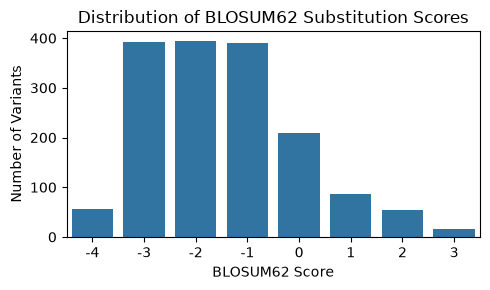

In [18]:
plt.figure(figsize=(5, 3))
sns.countplot(data=df,x="blosum62_score")
plt.xlabel("BLOSUM62 Score")
plt.ylabel("Number of Variants")
plt.title("Distribution of BLOSUM62 Substitution Scores")
plt.tight_layout()
plt.show()

In [19]:
subs_features = ["hydro_delta","charge_delta","volume_delta","blosum62_score"]
df[subs_features].corr().round(2)

,hydro_delta,charge_delta,volume_delta,blosum62_score
hydro_delta,1.00,0.10,-0.17,-0.56
charge_delta,0.10,1.00,-0.10,-0.08
volume_delta,-0.17,-0.10,1.00,-0.37
blosum62_score,-0.56,-0.08,-0.37,1.00


In [20]:
df[["blosum62_score", "label"]].corr().round(3)

,blosum62_score,label
blosum62_score,1.000,-0.112
label,-0.112,1.000


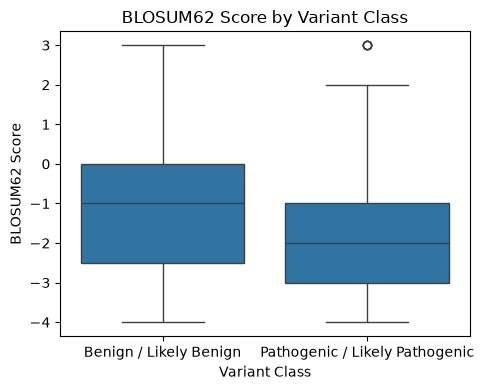

In [21]:
plt.figure(figsize=(5, 4))
sns.boxplot(data=df,x="label",y="blosum62_score")
plt.xlabel("Variant Class")
plt.ylabel("BLOSUM62 Score")
plt.title("BLOSUM62 Score by Variant Class")
plt.xticks([0, 1],["Benign / Likely Benign", "Pathogenic / Likely Pathogenic"])
plt.tight_layout()
plt.show()

**Grantham distance**: physicochemical severity of the amino-acid change

combines differences in composition, polarity, and molecular volume into one distance. <br>
Larger distance means a more radical substitution (represent greater amino-acid dissimilarity) <br>

Resources:
- [https://www.pattern.institute/grantham/](https://www.pattern.institute/grantham/)
- [https://slowkow.github.io/hlabud/reference/grantham.html](https://slowkow.github.io/hlabud/reference/grantham.html)

In [22]:
# Amino-acid properties
# 3 columns represent - 
# Composition c, the atomic weight ratio of noncarbon elements in end groups or rings to carbons in the side chain
# Polarity p
# Volume v 

grantham_properties = {
    "A": (0.00, 8.1, 31.0),
    "R": (0.65, 10.5, 124.0),
    "N": (1.33, 11.6, 56.0),
    "D": (1.38, 13.0, 54.0),
    "C": (2.75, 5.5, 55.0),
    "Q": (0.89, 10.5, 85.0),
    "E": (0.92, 12.3, 83.0),
    "G": (0.74, 9.0, 3.0),
    "H": (0.58, 10.4, 96.0),
    "I": (0.00, 5.2, 111.0),
    "L": (0.00, 4.9, 111.0),
    "K": (0.33, 11.3, 119.0),
    "M": (0.00, 5.7, 105.0),
    "F": (0.00, 5.2, 132.0),
    "P": (0.39, 8.0, 32.5),
    "S": (1.42, 9.2, 32.0),
    "T": (0.71, 8.6, 61.0),
    "W": (0.13, 5.4, 170.0),
    "Y": (0.20, 6.2, 136.0),
    "V": (0.00, 5.9, 84.0)
}

Grantham distance formula:

𝑑(i,j) = 𝜌(𝛼(c(i) - c(j))\*\*2 + 𝛽(p(i) - p(j))\*\*2 𝛾(v(i) - v(j))\*\*2)\*\*0.5

- alpha = 1.833,
- beta = 0.1018,
- gamma = 0.000399,
- rho = 50.723


Range: 5 to 215

[https://www.pattern.institute/grantham/reference/grantham_equation.html](https://www.pattern.institute/grantham/reference/grantham_equation.html)

In [23]:
def calculate_grantham_distance(ref_aa, alt_aa):
    ref_c, ref_p, ref_v = grantham_properties[ref_aa]
    alt_c, alt_p, alt_v = grantham_properties[alt_aa]

    composition_diff = ref_c - alt_c
    polarity_diff = ref_p - alt_p
    volume_diff = ref_v - alt_v

    distance = 50.723 * (1.833 * composition_diff**2+ 0.1018 * polarity_diff**2+ 0.000399 * volume_diff**2) ** 0.5

    return round(distance)

In [24]:
print("S -> E:", calculate_grantham_distance("S", "E"))
print("G -> R:", calculate_grantham_distance("G", "R"))
print("I -> L:", calculate_grantham_distance("I", "L"))

S -> E: 80
G -> R: 125
I -> L: 5


Verified the values from a reliable source:

[www.biorxiv.org/](https://www.biorxiv.org/highwire/markup/5660494/expansion?width=1000&height=500&iframe=true&postprocessors=highwire_tables%2Chighwire_reclass%2Chighwire_figures%2Chighwire_math%2Chighwire_inline_linked_media%2Chighwire_embed)

In [25]:
df["grantham_distance"] = [calculate_grantham_distance(ref, alt)for ref, alt in zip(df["ref_aa"], df["alt_aa"])]

In [26]:
df[["protein_change","ref_aa","alt_aa","hydro_delta","charge_delta","volume_delta","blosum62_score","grantham_distance"]].head(10)

,protein_change,ref_aa,alt_aa,hydro_delta,charge_delta,volume_delta,blosum62_score,grantham_distance
0,p.C176G,C,G,2.9,0,48.4,-3,158
1,p.F773W,F,W,3.7,0,37.9,1,40
2,p.R1244W,R,W,3.6,1,54.4,-3,101
3,p.L36C,L,C,1.3,0,58.2,-1,197
4,p.I1205V,I,V,0.3,0,26.7,3,30
5,p.W332R,W,R,3.6,1,54.4,-3,101
6,p.T1653F,T,F,3.5,0,73.8,-2,103
7,p.E1033T,E,T,2.8,1,22.3,-1,66
8,p.W1630G,W,G,0.5,0,167.7,-2,184
9,p.Q381L,Q,L,7.3,0,22.9,-2,112


**Observation**:

High grantham distance -> low blosum62 score

In [27]:
df["grantham_distance"].isna().sum()

np.int64(0)

In [28]:
df["grantham_distance"].describe().round(2)

count    1600.00
mean      102.08
std        48.24
min         5.00
25%        67.00
50%        99.00
75%       135.00
max       214.00
Name: grantham_distance, dtype: float64

In [29]:
df.groupby(["ref_aa", "alt_aa"])["grantham_distance"].nunique().max()

np.int64(1)

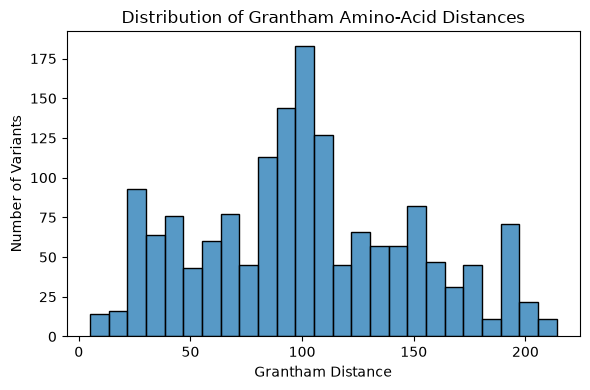

In [30]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df,x="grantham_distance",bins=25)
plt.xlabel("Grantham Distance")
plt.ylabel("Number of Variants")
plt.title("Distribution of Grantham Amino-Acid Distances")
plt.tight_layout()
plt.show()

In [31]:
subs_features = ["hydro_delta","charge_delta","volume_delta","blosum62_score","grantham_distance","label"]
df[subs_features].corr().round(3)

,hydro_delta,charge_delta,volume_delta,blosum62_score,grantham_distance,label
hydro_delta,1.000,0.099,-0.167,-0.561,0.288,0.108
charge_delta,0.099,1.000,-0.096,-0.080,0.073,0.064
volume_delta,-0.167,-0.096,1.000,-0.366,0.498,0.088
blosum62_score,-0.561,-0.080,-0.366,1.000,-0.638,-0.112
grantham_distance,0.288,0.073,0.498,-0.638,1.000,0.106
label,0.108,0.064,0.088,-0.112,0.106,1.000


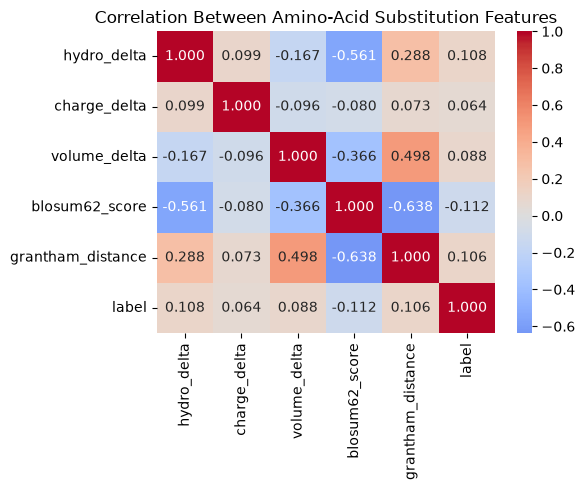

In [32]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[subs_features].corr(),annot=True,fmt=".3f",cmap="coolwarm",center=0)
plt.title("Correlation Between Amino-Acid Substitution Features")
plt.tight_layout()
plt.show()

In [33]:
df.groupby("label")[["blosum62_score", "grantham_distance"]].agg(["mean", "median", "std"]).round(3)

blosum62_score               grantham_distance               
                mean median    std              mean median     std
label                                                              
0             -1.325   -1.0  1.498            97.782   96.0  49.278
1             -1.660   -2.0  1.399           108.194  102.0  46.087

Interactive features:

- Grantham x pLDDT
- BLOSUM62 x pLDDT

In [34]:
df["grantham_plddt"] = (df["grantham_distance"] * df["plddt_at_pos"])

df["blosum_plddt"] = (df["blosum62_score"] * df["plddt_at_pos"])

df["grantham_plddt"].describe(), df["blosum_plddt"].describe()

(count     1600.000000
 mean      5872.005723
 std       3238.280365
 min        223.952381
 25%       3674.716898
 50%       5346.009735
 75%       7717.853423
 max      18984.335146
 Name: grantham_plddt, dtype: float64,
 count    1600.000000
 mean      -83.701645
 std        89.715625
 min      -349.664069
 25%      -144.784548
 50%       -88.160918
 75%       -41.521741
 max       258.164478
 Name: blosum_plddt, dtype: float64)

In [35]:
df[["blosum_plddt","grantham_plddt","label"]].corr().round(3)

,blosum_plddt,grantham_plddt,label
blosum_plddt,1.000,-0.665,-0.171
grantham_plddt,-0.665,1.000,0.216
label,-0.171,0.216,1.000


Blossum score is positive for favorable substitions while negative for unfavorable<br>
so, only keeping unfavorable would help model learn more about the substitutions

In [36]:
# clipping all positives to 0 and keeping the magintude of the negative ones
df["neg_blosum"] = (-df["blosum62_score"].clip(upper=0))
df["neg_blosum"].describe()

count    1600.000000
mean        1.615625
std         1.183218
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         4.000000
Name: neg_blosum, dtype: float64

In [37]:
# exploring how unfavorable the substitution is weighted by structural confidence of the residue
df["blosum_unfavorable_plddt"] = (df["neg_blosum"] * df["plddt_at_pos"])
df[["blosum_plddt","blosum_unfavorable_plddt","grantham_plddt","label"]].corr().round(3)

,blosum_plddt,blosum_unfavorable_plddt,grantham_plddt,label
blosum_plddt,1.000,-0.949,-0.665,-0.171
blosum_unfavorable_plddt,-0.949,1.000,0.671,0.184
grantham_plddt,-0.665,0.671,1.000,0.216
label,-0.171,0.184,0.216,1.000


Grantham x functional domain cols - interactive feature

In [38]:
df["in_functional_domain"] = (df["domain"] != "OTHER").astype(int)
df["grantham_domain"] = (df["grantham_distance"] * df["in_functional_domain"])

# OTHER - 0; RING/BRCT - Grantham distance

[Hydrophobicity scales](https://resources.qiagenbioinformatics.com/manuals/clcgenomicsworkbench/650/Hydrophobicity_scales.html)

Kyte-Doolittle scale - detecting hydrophobic regions in proteins. <br>
Regions with a positive value are hydrophobic



In [39]:
hydrophobicity = {
    "A": 1.8,
    "R": -4.5,
    "N": -3.5,
    "D": -3.5,
    "C": 2.5,
    "Q": -3.5,
    "E": -3.5,
    "G": -0.4,
    "H": -3.2,
    "I": 4.5,
    "L": 3.8,
    "K": -3.9,
    "M": 1.9,
    "F": 2.8,
    "P": -1.6,
    "S": -0.8,
    "T": -0.7,
    "W": -0.9,
    "Y": -1.3,
    "V": 4.2
}

In [40]:
df["hydro_signed_delta"] = [hydrophobicity[alt] - hydrophobicity[ref] for ref, alt in zip(df["ref_aa"], df["alt_aa"])]
np.allclose(df["hydro_delta"],df["hydro_signed_delta"].abs())

True

In [41]:
df[["protein_change","ref_aa","alt_aa","hydro_delta","hydro_signed_delta"]].head(10)

,protein_change,ref_aa,alt_aa,hydro_delta,hydro_signed_delta
0,p.C176G,C,G,2.9,-2.9
1,p.F773W,F,W,3.7,-3.7
2,p.R1244W,R,W,3.6,3.6
3,p.L36C,L,C,1.3,-1.3
4,p.I1205V,I,V,0.3,-0.3
5,p.W332R,W,R,3.6,-3.6
6,p.T1653F,T,F,3.5,3.5
7,p.E1033T,E,T,2.8,2.8
8,p.W1630G,W,G,0.5,0.5
9,p.Q381L,Q,L,7.3,7.3


In [42]:
df["hydro_signed_delta"].describe().round(2)

count    1600.00
mean        0.02
std         4.28
min        -9.00
25%        -2.90
50%         0.00
75%         3.10
max         9.00
Name: hydro_signed_delta, dtype: float64

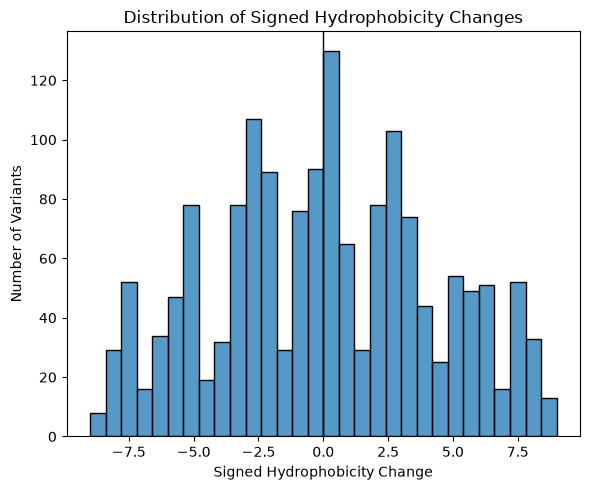

In [43]:
plt.figure(figsize=(6, 5))
sns.histplot(data=df,x="hydro_signed_delta",bins=30)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Signed Hydrophobicity Change")
plt.ylabel("Number of Variants")
plt.title("Distribution of Signed Hydrophobicity Changes")
plt.tight_layout()
plt.show()

In [44]:
df[["hydro_delta", "hydro_signed_delta", "label"]].corr().round(3)

,hydro_delta,hydro_signed_delta,label
hydro_delta,1.000,0.019,0.108
hydro_signed_delta,0.019,1.000,-0.009
label,0.108,-0.009,1.000


In [45]:
df.groupby("label")[["hydro_delta", "hydro_signed_delta"]].agg(["mean", "median", "std"]).round(2)

hydro_delta              hydro_signed_delta             
             mean median   std               mean median   std
label                                                         
0            3.28    2.8  2.44               0.06    0.0  4.09
1            3.82    3.2  2.43              -0.03   -0.1  4.53

Volume matrix to calculate signed volume change for each substitution

- [https://www.thegpm.org/BIOML/aainfo/volume.htm?utm_source=chatgpt.com](https://www.thegpm.org/BIOML/aainfo/volume.htm?utm_source=chatgpt.com)

In [46]:
aa_volume = {
    "A": 88.6,
    "R": 173.4,
    "N": 114.1,
    "D": 111.1,
    "C": 108.5,
    "Q": 143.8,
    "E": 138.4,
    "G": 60.1,
    "H": 153.2,
    "I": 166.7,
    "L": 166.7,
    "K": 168.6,
    "M": 162.9,
    "F": 189.9,
    "P": 112.7,
    "S": 89.0,
    "T": 116.1,
    "W": 227.8,
    "Y": 193.6,
    "V": 140.0
}

df["volume_signed_delta"] = [aa_volume[alt] - aa_volume[ref]for ref, alt in zip(df["ref_aa"], df["alt_aa"])]
np.allclose(df["volume_delta"],df["volume_signed_delta"].abs())

True

In [47]:
df[["protein_change","ref_aa","alt_aa","volume_delta","volume_signed_delta"]].head(10)

,protein_change,ref_aa,alt_aa,volume_delta,volume_signed_delta
0,p.C176G,C,G,48.4,-48.4
1,p.F773W,F,W,37.9,37.9
2,p.R1244W,R,W,54.4,54.4
3,p.L36C,L,C,58.2,-58.2
4,p.I1205V,I,V,26.7,-26.7
5,p.W332R,W,R,54.4,-54.4
6,p.T1653F,T,F,73.8,73.8
7,p.E1033T,E,T,22.3,-22.3
8,p.W1630G,W,G,167.7,-167.7
9,p.Q381L,Q,L,22.9,22.9


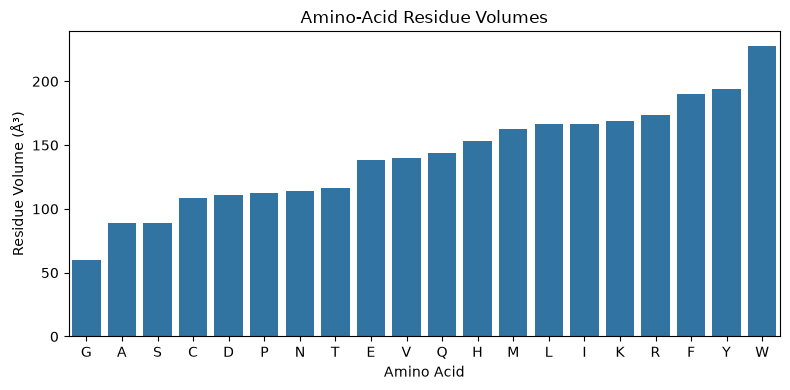

In [48]:
volume_df = pd.DataFrame({"amino_acid": aa_volume.keys(),"volume": aa_volume.values()}).sort_values("volume")

plt.figure(figsize=(8, 4))
sns.barplot(data=volume_df,x="amino_acid",y="volume")
plt.xlabel("Amino Acid")
plt.ylabel("Residue Volume (Å³)")
plt.title("Amino-Acid Residue Volumes")
plt.tight_layout()
plt.show()

In [51]:
df.columns

Index(['variation_id', 'gene_symbol', 'protein_change', 'protein_position',
       'ref_aa', 'alt_aa', 'clinical_significance', 'domain', 'plddt',
       'is_stop_gained', 'is_frameshift', 'is_splice_region', 'label',
       'pos_norm', 'distance_to_domain', 'plddt_at_pos', 'plddt_window11',
       'hydro_delta', 'charge_delta', 'volume_delta', 'domain_BRCT1',
       'domain_BRCT2', 'domain_OTHER', 'domain_RING', 'plddt_delta',
       'plddt_neighbor_mean_est', 'plddt_neighbor_delta',
       'in_functional_domain', 'blosum62_score', 'grantham_distance',
       'grantham_plddt', 'blosum_plddt', 'neg_blosum',
       'blosum_unfavorable_plddt', 'grantham_domain', 'hydro_signed_delta',
       'volume_signed_delta'],
      dtype='str')

In [53]:
corr_matrix = df.select_dtypes(include="number").corr(method="spearman")

target_corr = corr_matrix["label"].sort_values(ascending=False)
print(target_corr)

label                       1.000000
grantham_domain             0.292389
in_functional_domain        0.288881
is_stop_gained              0.275513
is_frameshift               0.252775
is_splice_region            0.208345
plddt_at_pos                0.205527
grantham_plddt              0.204539
plddt_window11              0.201834
plddt_neighbor_mean_est     0.200652
plddt                       0.189059
blosum_unfavorable_plddt    0.166970
hydro_delta                 0.110617
neg_blosum                  0.108072
grantham_distance           0.107974
volume_delta                0.095548
charge_delta                0.062543
volume_signed_delta         0.056605
variation_id                0.039316
plddt_neighbor_delta        0.030658
plddt_delta                 0.030658
hydro_signed_delta         -0.012509
protein_position           -0.012578
pos_norm                   -0.012578
blosum62_score             -0.112580
blosum_plddt               -0.169796
distance_to_domain         -0.198264
N